In [ ]:
import numpy as np
import cobra
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pickle
import sys
import pandas as pd
import os
from scipy.stats import spearmanr
sys.path.append('../../')
from helper_function import *
plt.rcParams['font.family'] = 'Arial'
cobra.Configuration().solver = 'glpk'

In [3]:
model = cobra.io.load_matlab_model('../../universal_model.mat')

Set parameter Username
Academic license - for non-commercial use only - expires 2026-08-29


In [ ]:
S_df = cobra.util.create_stoichiometric_matrix(model, array_type='DataFrame')
reaction_list = list(S_df.columns)
metabolite_list = list(S_df.index)

In [ ]:
import pandas as pd
modelname = pd.read_excel('../../AGORA2_models/ModelList.xlsx')
modelname = np.array(modelname['ModelName'])

In [ ]:
def load_selected_model_from_directory(directory, excel_file):
    sheet_name = 'Sheet1'
    column_name = 'ModelName'
    model_names_df = pd.read_excel(excel_file, sheet_name=sheet_name)
    models = []
    for model_name in model_names_df[column_name]:
        filename = f"{model_name}"
        model_path = os.path.join(directory, filename[1:-1])
        if os.path.exists(model_path):
            try:
                print(f"Loading {filename}...")
                models.append(model_path)
                print(f"Successfully loaded model: {filename}")
            except Exception as e:
                print(f"Failed to load model from file: {filename}")
                print(f"Error: {e}")
        else:
            print(f"File {filename} does not exist in the directory.")
    return models

directory = '../../AGORA2_models'
excel_file = '../../AGORA2_models/ModelList.xlsx'
models = load_selected_model_from_directory(directory=directory, excel_file=excel_file)

Loading 'Acidaminococcus_fermentans_DSM_20731.mat'...
Successfully loaded model: 'Acidaminococcus_fermentans_DSM_20731.mat'
Loading 'Acinetobacter_baumannii_ATCC_19606.mat'...
Successfully loaded model: 'Acinetobacter_baumannii_ATCC_19606.mat'
Loading 'Acinetobacter_haemolyticus_ATCC_19194.mat'...
Successfully loaded model: 'Acinetobacter_haemolyticus_ATCC_19194.mat'
Loading 'Adlercreutzia_equolifaciens_DSM_19450.mat'...
Successfully loaded model: 'Adlercreutzia_equolifaciens_DSM_19450.mat'
Loading 'Akkermansia_muciniphila_ATCC_BAA_835.mat'...
Successfully loaded model: 'Akkermansia_muciniphila_ATCC_BAA_835.mat'
Loading 'Alistipes_onderdonkii_DSM_19147.mat'...
Successfully loaded model: 'Alistipes_onderdonkii_DSM_19147.mat'
Loading 'Bacillus_subtilis_B_1.mat'...
Successfully loaded model: 'Bacillus_subtilis_B_1.mat'
Loading 'Bacteroides_caccae_ATCC_43185.mat'...
Successfully loaded model: 'Bacteroides_caccae_ATCC_43185.mat'
Loading 'Bacteroides_cellulosilyticus_DSM_14838.mat'...
Succes

In [8]:
# Initialize a list to store the binary vectors for each model
model_reaction_vectors = []

# Iterate through each model path
for model_path in models:
    try:
        # Load the model
        current_model = cobra.io.load_matlab_model(model_path)
        
        # Get the set of reaction IDs in the current model for fast lookup
        current_model_reactions = set(r.id for r in current_model.reactions)
        
        # Create the 0-1 vector based on reaction_list
        # 1 if the reaction is present in the current model, 0 otherwise
        vector = [1 if rxn_id in current_model_reactions else 0 for rxn_id in reaction_list]
        
        # Append the vector to the list
        model_reaction_vectors.append(vector)
        
    except Exception as e:
        print(f"Error processing model {model_path}: {e}")
        # In case of error, you might want to append a zero vector or handle it differently
        # Here we append a zero vector of the same length to keep indices aligned
        model_reaction_vectors.append([0] * len(reaction_list))

# Convert the list of vectors to a numpy array for easier analysis
model_reaction_matrix = np.array(model_reaction_vectors)

print(f"Constructed matrix shape: {model_reaction_matrix.shape}")


No defined compartments in model model. Compartments will be deduced heuristically using regular expressions.
Using regular expression found the following compartments:c, e, p
No defined compartments in model model. Compartments will be deduced heuristically using regular expressions.
Using regular expression found the following compartments:c, e, p
No defined compartments in model model. Compartments will be deduced heuristically using regular expressions.
Using regular expression found the following compartments:c, e, p
No defined compartments in model model. Compartments will be deduced heuristically using regular expressions.
Using regular expression found the following compartments:c, e
No defined compartments in model model. Compartments will be deduced heuristically using regular expressions.
Using regular expression found the following compartments:c, e, p
No defined compartments in model model. Compartments will be deduced heuristically using regular expressions.
Using regular

Constructed matrix shape: (205, 7425)


In [ ]:
with open('../../FBAsolution/M9_sufficient_423_1_proteome_weakbg.pkl', 'rb') as pickle_file:
    data = pickle.load(pickle_file)
    all_total_nutrient_count = data['all_total_nutrient_count']
    all_total_intake = data['all_total_intake']
    all_growth_rate = data['all_growth_rate']
    all_random_medium = data['all_random_medium']
    all_met_flux = data['all_met_flux']
    del data

In [10]:
model_active_reaction_vectors = []

# Iterate through each model path
for met_flux in all_met_flux[0]:
    try:
        # Create the 0-1 vector based on reaction_list
        # 1 if the reaction is present in the current model, 0 otherwise
        vectors = []
        for rec_id in reaction_list:
            flux = dict(met_flux).get(rec_id, 0)
            if abs(flux) > 0:
                vectors.append(1)
            else:
                vectors.append(0)
        model_active_reaction_vectors.append(vectors)
        
    except Exception as e:
        print(f"Error processing model {model_path}: {e}")
        # In case of error, you might want to append a zero vector or handle it differently
        # Here we append a zero vector of the same length to keep indices aligned
        model_active_reaction_vectors.append([0] * len(reaction_list))

# Convert the list of vectors to a numpy array for easier analysis
model_active_reaction_matrix = np.array(model_active_reaction_vectors)

In [ ]:
from scipy.spatial.distance import pdist

dist_matrix2 = pdist(model_active_reaction_matrix, metric='Jaccard')
variation = dist_matrix2.mean()

dist_matrix = pdist(model_reaction_matrix, metric='Jaccard')
variation = dist_matrix.mean()


Variation (0-1): 0.6786


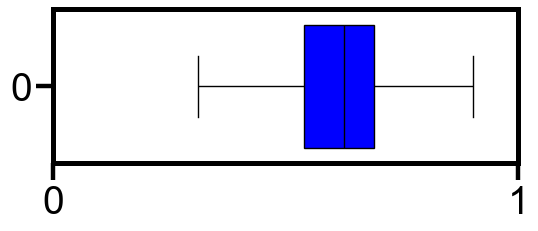

In [ ]:
set_panel_style(scale=4)
plt.figure(figsize=(6, 2))
sns.boxplot(
    data=[dist_matrix],
    orient='h',
    showfliers=False,
    boxprops=dict(facecolor='blue', edgecolor='black'),  # 填充色 + 黑色边框
    medianprops=dict(color='black'),                          # 中位数线颜色
    whiskerprops=dict(color='black'),                         # 箱须颜色
    capprops=dict(color='black')                              # 顶端横线颜色
)
plt.xticks([0, 1], ['0', '1'])
#plt.savefig(f"Figure1_1.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()

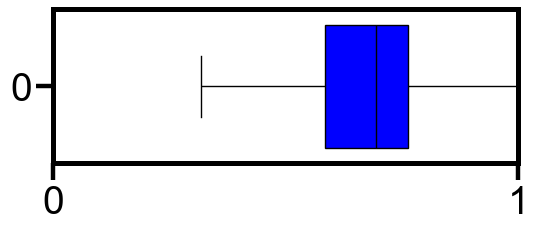

In [ ]:
plt.figure(figsize=(6, 2))
sns.boxplot(
    data=[dist_matrix2],
    orient='h',
    showfliers=False,
    boxprops=dict(facecolor='blue', edgecolor='black'),  # 填充色 + 黑色边框
    medianprops=dict(color='black'),                          # 中位数线颜色
    whiskerprops=dict(color='black'),                         # 箱须颜色
    capprops=dict(color='black')                              # 顶端横线颜色
)
plt.xticks([0, 1], ['0', '1'])
plt.xlim(0, 1)
#plt.savefig(f"Figure1_2.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()